In [4]:
# Import library dasar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Import library scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve,
    precision_score, recall_score, f1_score
)

# Tambahan (dibutuhkan oleh sel-sel berikutnya)
from sklearn.preprocessing import label_binarize
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
import io, json, time, joblib
from pathlib import Path

# Setting tampilan
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
%matplotlib inline

print("Semua library berhasil diimport!")

Semua library berhasil diimport!


In [5]:
# Load dataset
df = pd.read_csv('faults.csv')

# Tampilkan informasi awal
print("Ukuran dataset:", df.shape)
print("\n5 Baris Pertama:")
df.head()

Ukuran dataset: (1941, 34)

5 Baris Pertama:


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


In [6]:
# Rapikan nama kolom (hapus spasi) dan samakan ejaan K_Scratch -> K_Scatch
df.columns = df.columns.astype(str).str.strip()
if 'K_Scratch' in df.columns and 'K_Scatch' not in df.columns:
    df = df.rename(columns={'K_Scratch': 'K_Scatch'})

# 7 kolom label (one-hot) dan 27 kolom fitur
FAULT_TYPES = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains',
               'Dirtiness', 'Bumps', 'Other_Faults']
FEATURES = [c for c in df.columns if c not in FAULT_TYPES]

print("Jumlah fitur :", len(FEATURES))
print("Jumlah label :", len(FAULT_TYPES))
assert len(FEATURES) == 27, "Jumlah fitur tidak 27, periksa kolom dataset"

Jumlah fitur : 27
Jumlah label : 7


In [7]:
# Tipe data, nilai kosong, dan duplikat
print("Nilai kosong total :", int(df.isna().sum().sum()))
print("Baris duplikat     :", int(df.duplicated().sum()))
print("Semua fitur numerik:", all(pd.api.types.is_numeric_dtype(df[c]) for c in FEATURES))
df[FEATURES].describe().T.round(2)

Nilai kosong total : 0
Baris duplikat     : 0
Semua fitur numerik: True


,count,mean,std,min,25%,50%,75%,max
X_Minimum,1941.0,571.14,520.69,0.00,51.00,435.00,1053.00,1705.00
X_Maximum,1941.0,617.96,497.63,4.00,192.00,467.00,1072.00,1713.00
Y_Minimum,1941.0,1650684.87,1774578.41,6712.00,471253.00,1204128.00,2183073.00,12987661.00
Y_Maximum,1941.0,1650738.71,1774590.09,6724.00,471281.00,1204136.00,2183084.00,12987692.00
Pixels_Areas,1941.0,1893.88,5168.46,2.00,84.00,174.00,822.00,152655.00
X_Perimeter,1941.0,111.86,301.21,2.00,15.00,26.00,84.00,10449.00
Y_Perimeter,1941.0,82.97,426.48,1.00,13.00,25.00,83.00,18152.00
Sum_of_Luminosity,1941.0,206312.15,512293.59,250.00,9522.00,19202.00,83011.00,11591414.00
Minimum_of_Luminosity,1941.0,84.55,32.13,0.00,63.00,90.00,106.00,203.00
Maximum_of_Luminosity,1941.0,130.19,18.69,37.00,124.00,127.00,140.00,253.00


In [8]:
# Validasi: tiap baris tepat satu label aktif
valid = (df[FAULT_TYPES].isin([0, 1]).all(axis=1)) & (df[FAULT_TYPES].sum(axis=1) == 1)
print("Semua baris punya tepat 1 label:", bool(valid.all()))

# Ubah 7 kolom menjadi 1 kolom nama cacat
y_str = df[FAULT_TYPES].idxmax(axis=1)

# Encode ke angka 0-6 (dibutuhkan untuk ROC-AUC)
le = LabelEncoder().fit(y_str)
y = pd.Series(le.transform(y_str), index=df.index, name='Fault_Type')
x = df[FEATURES].astype(float)

print("\nKelas (urutan encoding):", list(le.classes_))
dist = y_str.value_counts()
print("\nDistribusi kelas:")
print(pd.DataFrame({'jumlah': dist, 'persen': (dist / len(y_str) * 100).round(1)}))

Semua baris punya tepat 1 label: True

Kelas (urutan encoding): ['Bumps', 'Dirtiness', 'K_Scatch', 'Other_Faults', 'Pastry', 'Stains', 'Z_Scratch']

Distribusi kelas:
              jumlah  persen
Other_Faults     673    34.7
Bumps            402    20.7
K_Scatch         391    20.1
Z_Scratch        190     9.8
Pastry           158     8.1
Stains            72     3.7
Dirtiness         55     2.8


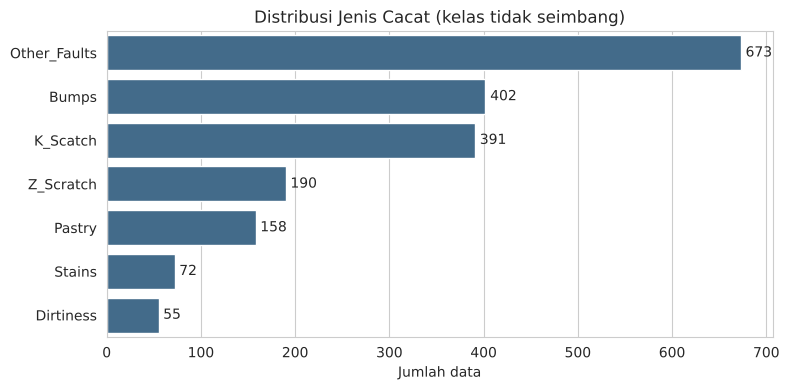

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=dist.values, y=dist.index, color='#376c96', ax=ax)
ax.set(xlabel='Jumlah data', ylabel='', title='Distribusi Jenis Cacat (kelas tidak seimbang)')
for i, v in enumerate(dist.values):
    ax.text(v + 5, i, str(v), va='center')
plt.tight_layout(); plt.show()

In [10]:
(x_train, x_test, y_train, y_test,
 ys_train, ys_test) = train_test_split(
    x, y, y_str, test_size=0.20, random_state=42, stratify=y
)
print("Data latih:", x_train.shape, "| Data uji:", x_test.shape)

Data latih: (1552, 27) | Data uji: (389, 27)


In [11]:
N_FEATURES = 17   # <- ubah di sini jika ingin jumlah lain

def make_selector():
    return RandomForestClassifier(
        n_estimators=300, random_state=42,
        class_weight='balanced_subsample', n_jobs=-1)

ranker = make_selector().fit(x_train, y_train)
importance = pd.Series(ranker.feature_importances_, index=FEATURES).sort_values(ascending=False)

FEATURES_17 = importance.head(N_FEATURES).index.tolist()
DIBUANG = [c for c in FEATURES if c not in FEATURES_17]

print(f"Dipertahankan ({len(FEATURES_17)}):", FEATURES_17)
print(f"\nDibuang ({len(DIBUANG)}):", DIBUANG)

Dipertahankan (17): ['Length_of_Conveyer', 'LogOfAreas', 'Pixels_Areas', 'Outside_X_Index', 'Sum_of_Luminosity', 'X_Minimum', 'Minimum_of_Luminosity', 'Orientation_Index', 'Square_Index', 'Steel_Plate_Thickness', 'Log_X_Index', 'X_Maximum', 'Edges_Index', 'SigmoidOfAreas', 'Y_Minimum', 'Y_Maximum', 'Edges_Y_Index']

Dibuang (10): ['X_Perimeter', 'Y_Perimeter', 'Maximum_of_Luminosity', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Empty_Index', 'Edges_X_Index', 'Outside_Global_Index', 'Log_Y_Index', 'Luminosity_Index']


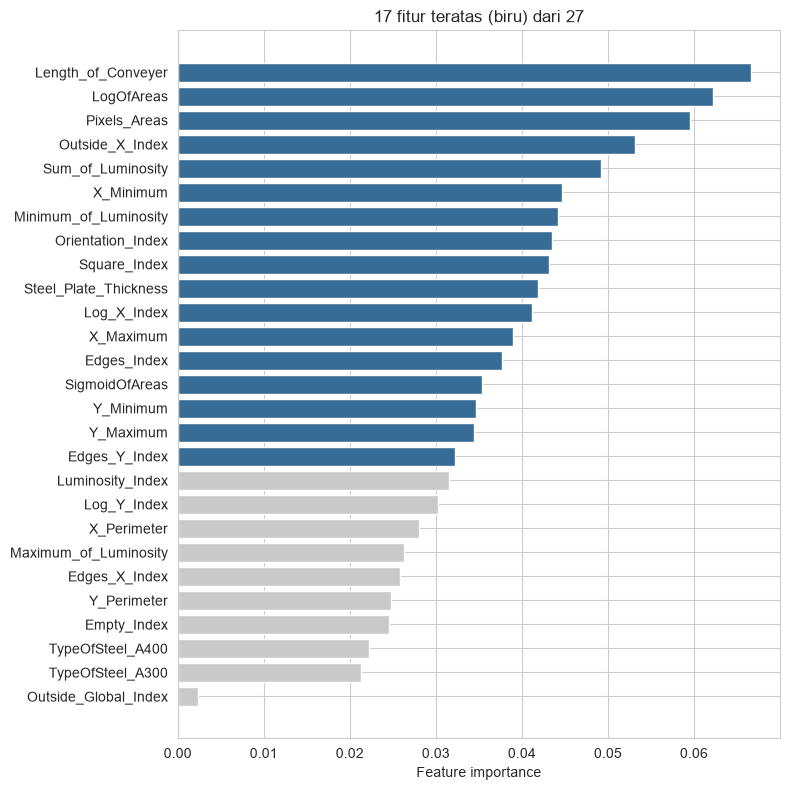

In [12]:
fig, ax = plt.subplots(figsize=(8, 8))
warna = ['#376c96' if c in FEATURES_17 else '#c9c9c9' for c in importance.index]
ax.barh(importance.index, importance.values, color=warna)
ax.invert_yaxis()
ax.set(xlabel='Feature importance',
       title=f'{N_FEATURES} fitur teratas (biru) dari {len(FEATURES)}')
plt.tight_layout(); plt.show()

In [13]:
MODELS = {
    'Decision Tree': lambda: DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=3, class_weight='balanced', random_state=42),
    'KNN': lambda: KNeighborsClassifier(n_neighbors=7, weights='distance'),
    'Naive Bayes': lambda: GaussianNB(),
    'Logistic Regression': lambda: LogisticRegression(
        max_iter=3000, class_weight='balanced', random_state=42),
    'Random Forest': lambda: RandomForestClassifier(
        n_estimators=150, class_weight='balanced_subsample',
        random_state=42, n_jobs=-1),
}

def make_pipe(name, select_features=None):
    """Pipeline: (opsional) seleksi fitur -> scaler -> model."""
    steps = []
    if select_features:
        steps.append(('select', SelectFromModel(
            make_selector(), max_features=select_features, threshold=-np.inf)))
    steps += [('scaler', StandardScaler()), ('model', MODELS[name]())]
    return Pipeline(steps)

def evaluate(name, cols):
    """Latih pada data latih, ukur pada data uji."""
    pipe = make_pipe(name).fit(x_train[cols], y_train)
    pred = pipe.predict(x_test[cols])
    proba = pipe.predict_proba(x_test[cols])
    row = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (macro)': precision_score(y_test, pred, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_test, pred, average='macro', zero_division=0),
        'F1 (macro)': f1_score(y_test, pred, average='macro', zero_division=0),
        'ROC-AUC (OvR)': roc_auc_score(y_test, proba, multi_class='ovr', average='macro'),
    }
    return pipe, pred, proba, row

In [11]:
fitted_17, preds_17, probas_17, rows = {}, {}, {}, []
for name in MODELS:
    fitted_17[name], preds_17[name], probas_17[name], row = evaluate(name, FEATURES_17)
    rows.append(row)

hasil_17 = (pd.DataFrame(rows).set_index('Model')
            .sort_values('F1 (macro)', ascending=False).round(4))
hasil_17

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR)
Model,,,,,
Random Forest,0.7738,0.8293,0.7787,0.8011,0.9598
KNN,0.7172,0.7286,0.7528,0.7379,0.9275
Decision Tree,0.6915,0.6795,0.7536,0.7032,0.8717
Logistic Regression,0.6247,0.5945,0.7315,0.6175,0.9183
Naive Bayes,0.5887,0.6080,0.6861,0.6049,0.9119


Perbandingan dengan data 27


In [14]:
fitted_17, preds_17, probas_17, rows = {}, {}, {}, []
for name in MODELS:
    fitted_17[name], preds_17[name], probas_17[name], row = evaluate(name, FEATURES_17)
    rows.append(row)

hasil_17 = (pd.DataFrame(rows).set_index('Model')
            .sort_values('F1 (macro)', ascending=False).round(4))
hasil_17

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR)
Model,,,,,
Random Forest,0.7712,0.8363,0.7528,0.7867,0.9570
KNN,0.7172,0.7286,0.7528,0.7379,0.9275
Decision Tree,0.6992,0.6845,0.7595,0.7093,0.8755
Logistic Regression,0.6247,0.5945,0.7315,0.6175,0.9183
Naive Bayes,0.5887,0.6080,0.6861,0.6049,0.9119


### Perbandingan Dengan data 27

In [15]:
N_FEATURES = 17   # <- ubah di sini jika ingin membandingkan jumlah lain

ranker = make_selector().fit(x_train, y_train)
importance = pd.Series(ranker.feature_importances_, index=FEATURES).sort_values(ascending=False)
FEATURES_17 = importance.head(N_FEATURES).index.tolist()
DIBUANG = [c for c in FEATURES if c not in FEATURES_17]

print(f"Dipertahankan ({len(FEATURES_17)}):", FEATURES_17)
print(f"\nDibuang ({len(DIBUANG)}):", DIBUANG)

Dipertahankan (17): ['Length_of_Conveyer', 'LogOfAreas', 'Pixels_Areas', 'Outside_X_Index', 'Sum_of_Luminosity', 'X_Minimum', 'Minimum_of_Luminosity', 'Orientation_Index', 'Square_Index', 'Steel_Plate_Thickness', 'Log_X_Index', 'X_Maximum', 'Edges_Index', 'SigmoidOfAreas', 'Y_Minimum', 'Y_Maximum', 'Edges_Y_Index']

Dibuang (10): ['X_Perimeter', 'Y_Perimeter', 'Maximum_of_Luminosity', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Empty_Index', 'Edges_X_Index', 'Outside_Global_Index', 'Log_Y_Index', 'Luminosity_Index']


In [16]:
# Rapikan nama kolom dan samakan ejaan K_Scratch -> K_Scatch
df.columns = df.columns.astype(str).str.strip()
if 'K_Scratch' in df.columns and 'K_Scatch' not in df.columns:
    df = df.rename(columns={'K_Scratch': 'K_Scatch'})

# 7 kolom label (one-hot) dan 27 kolom fitur
FAULT_TYPES = ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains',
               'Dirtiness', 'Bumps', 'Other_Faults']
FEATURES = [c for c in df.columns if c not in FAULT_TYPES]

print("Jumlah fitur :", len(FEATURES))
print("Jumlah label :", len(FAULT_TYPES))
assert len(FEATURES) == 27, "Jumlah fitur tidak 27, periksa kolom dataset"

Jumlah fitur : 27
Jumlah label : 7


In [17]:
print("Nilai kosong total :", int(df.isna().sum().sum()))
print("Baris duplikat     :", int(df.duplicated().sum()))
print("Semua fitur numerik:", all(pd.api.types.is_numeric_dtype(df[c]) for c in FEATURES))
df[FEATURES].describe().T.round(2)

Nilai kosong total : 0
Baris duplikat     : 0
Semua fitur numerik: True


,count,mean,std,min,25%,50%,75%,max
X_Minimum,1941.0,571.14,520.69,0.00,51.00,435.00,1053.00,1705.00
X_Maximum,1941.0,617.96,497.63,4.00,192.00,467.00,1072.00,1713.00
Y_Minimum,1941.0,1650684.87,1774578.41,6712.00,471253.00,1204128.00,2183073.00,12987661.00
Y_Maximum,1941.0,1650738.71,1774590.09,6724.00,471281.00,1204136.00,2183084.00,12987692.00
Pixels_Areas,1941.0,1893.88,5168.46,2.00,84.00,174.00,822.00,152655.00
X_Perimeter,1941.0,111.86,301.21,2.00,15.00,26.00,84.00,10449.00
Y_Perimeter,1941.0,82.97,426.48,1.00,13.00,25.00,83.00,18152.00
Sum_of_Luminosity,1941.0,206312.15,512293.59,250.00,9522.00,19202.00,83011.00,11591414.00
Minimum_of_Luminosity,1941.0,84.55,32.13,0.00,63.00,90.00,106.00,203.00
Maximum_of_Luminosity,1941.0,130.19,18.69,37.00,124.00,127.00,140.00,253.00


In [18]:
valid = (df[FAULT_TYPES].isin([0, 1]).all(axis=1)) & (df[FAULT_TYPES].sum(axis=1) == 1)
print("Semua baris punya tepat 1 label:", bool(valid.all()))

y_str = df[FAULT_TYPES].idxmax(axis=1)           # nama cacat
le = LabelEncoder().fit(y_str)                   # angka 0-6 (untuk ROC-AUC)
y = pd.Series(le.transform(y_str), index=df.index, name='Fault_Type')
x = df[FEATURES].astype(float)

print("\nKelas (urutan encoding):", list(le.classes_))
dist = y_str.value_counts()
print(pd.DataFrame({'jumlah': dist, 'persen': (dist / len(y_str) * 100).round(1)}))

Semua baris punya tepat 1 label: True

Kelas (urutan encoding): ['Bumps', 'Dirtiness', 'K_Scatch', 'Other_Faults', 'Pastry', 'Stains', 'Z_Scratch']
              jumlah  persen
Other_Faults     673    34.7
Bumps            402    20.7
K_Scatch         391    20.1
Z_Scratch        190     9.8
Pastry           158     8.1
Stains            72     3.7
Dirtiness         55     2.8


In [17]:
(x_train, x_test, y_train, y_test,
 ys_train, ys_test) = train_test_split(
    x, y, y_str, test_size=0.20, random_state=42, stratify=y
)
print("Data latih:", x_train.shape, "| Data uji:", x_test.shape)

Data latih: (1552, 27) | Data uji: (389, 27)


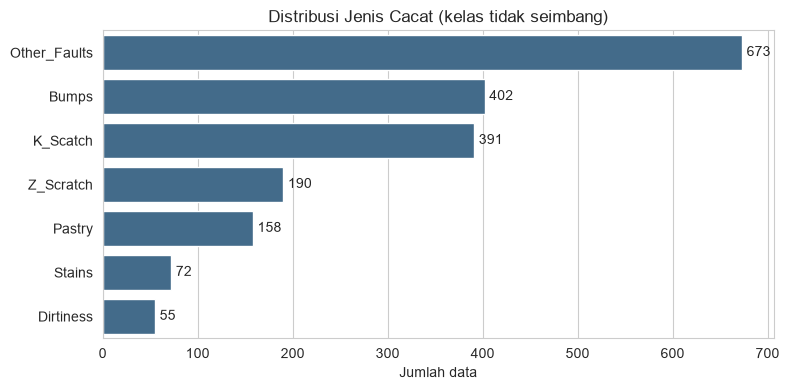

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=dist.values, y=dist.index, color='#376c96', ax=ax)
ax.set(xlabel='Jumlah data', ylabel='', title='Distribusi Jenis Cacat (kelas tidak seimbang)')
for i, v in enumerate(dist.values):
    ax.text(v + 5, i, str(v), va='center')
plt.tight_layout(); plt.show()

In [20]:
(x_train, x_test, y_train, y_test,
 ys_train, ys_test) = train_test_split(
    x, y, y_str, test_size=0.20, random_state=42, stratify=y
)
print("Data latih:", x_train.shape, "| Data uji:", x_test.shape)

Data latih: (1552, 27) | Data uji: (389, 27)


In [21]:
MODELS = {
    'Decision Tree': lambda: DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=3, class_weight='balanced', random_state=42),
    'KNN': lambda: KNeighborsClassifier(n_neighbors=7, weights='distance'),
    'Naive Bayes': lambda: GaussianNB(),
    'Logistic Regression': lambda: LogisticRegression(
        max_iter=3000, class_weight='balanced', random_state=42),
    'Random Forest': lambda: RandomForestClassifier(
        n_estimators=150, class_weight='balanced_subsample',
        random_state=42, n_jobs=-1),
}

def make_selector():
    # Dipakai untuk memilih fitur (hanya untuk Bagian B)
    return RandomForestClassifier(
        n_estimators=300, random_state=42,
        class_weight='balanced_subsample', n_jobs=-1)

def make_pipe(name, select_features=None):
    """Pipeline: (opsional) seleksi fitur -> scaler -> model."""
    steps = []
    if select_features:
        steps.append(('select', SelectFromModel(
            make_selector(), max_features=select_features, threshold=-np.inf)))
    steps += [('scaler', StandardScaler()), ('model', MODELS[name]())]
    return Pipeline(steps)

def evaluate(name, cols):
    """Latih pada data latih, ukur pada data uji (termasuk waktu)."""
    pipe = make_pipe(name)
    t0 = time.perf_counter()
    pipe.fit(x_train[cols], y_train)
    waktu_latih = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred = pipe.predict(x_test[cols])
    waktu_prediksi = time.perf_counter() - t0
    proba = pipe.predict_proba(x_test[cols])

    row = {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (macro)': precision_score(y_test, pred, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_test, pred, average='macro', zero_division=0),
        'F1 (macro)': f1_score(y_test, pred, average='macro', zero_division=0),
        'ROC-AUC (OvR)': roc_auc_score(y_test, proba, multi_class='ovr', average='macro'),
        'Waktu latih (s)': waktu_latih,
        'Waktu prediksi (s)': waktu_prediksi,
    }
    return pipe, pred, proba, row

In [22]:
fitted_27, preds_27, probas_27, rows = {}, {}, {}, []
for name in MODELS:
    fitted_27[name], preds_27[name], probas_27[name], row = evaluate(name, FEATURES)
    rows.append(row)

hasil_27 = (pd.DataFrame(rows).set_index('Model')
            .sort_values('F1 (macro)', ascending=False))
hasil_27.round(4)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR),Waktu latih (s),Waktu prediksi (s)
Model,,,,,,,
Random Forest,0.8046,0.8692,0.8016,0.8315,0.9624,0.5482,0.0522
KNN,0.7558,0.7453,0.7687,0.7546,0.9251,0.0046,0.0108
Decision Tree,0.6941,0.6638,0.7267,0.6825,0.8724,0.0432,0.0024
Logistic Regression,0.6452,0.6115,0.7311,0.6365,0.9327,0.0601,0.0019
Naive Bayes,0.6093,0.6333,0.7169,0.6339,0.9225,0.0063,0.0039


In [23]:
# Perbandingan hasil supervised learning: 17 fitur vs 27 fitur
# Pastikan cell evaluasi 17 fitur (hasil_17) dan 27 fitur (hasil_27) sudah dijalankan.

metrik = [
    "Accuracy",
    "Precision (macro)",
    "Recall (macro)",
    "F1 (macro)",
    "ROC-AUC (OvR)"
]

# Ambil hanya metrik yang tersedia di kedua tabel
metrik_tersedia = [
    kolom for kolom in metrik
    if kolom in hasil_17.columns and kolom in hasil_27.columns
]

perbandingan_17_27 = pd.concat(
    {
        "17 fitur": hasil_17[metrik_tersedia],
        "27 fitur": hasil_27[metrik_tersedia]
    },
    axis=1
)

print("Perbandingan metrik untuk setiap model:")
display(perbandingan_17_27.round(4))

# Bandingkan F1 macro, metrik utama untuk melihat performa semua kelas secara seimbang
f1_compare = pd.DataFrame({
    "F1 Macro (17 fitur)": hasil_17["F1 (macro)"],
    "F1 Macro (27 fitur)": hasil_27["F1 (macro)"]
})
f1_compare["Selisih (27 - 17)"] = (
    f1_compare["F1 Macro (27 fitur)"] - f1_compare["F1 Macro (17 fitur)"]
)

print("\nPerbandingan F1 Macro (nilai positif berarti 27 fitur lebih baik):")
display(f1_compare.sort_values("Selisih (27 - 17)", ascending=False).round(4))

# Ringkasan model terbaik untuk masing-masing jumlah fitur berdasarkan F1 macro
best_17_name = hasil_17["F1 (macro)"].idxmax()
best_27_name = hasil_27["F1 (macro)"].idxmax()
best_17_f1 = hasil_17.loc[best_17_name, "F1 (macro)"]
best_27_f1 = hasil_27.loc[best_27_name, "F1 (macro)"]

print("\nRingkasan:")
print(f"17 fitur: model terbaik = {best_17_name}, F1 Macro = {best_17_f1:.4f}")
print(f"27 fitur: model terbaik = {best_27_name}, F1 Macro = {best_27_f1:.4f}")
print(f"Selisih F1 Macro (27 - 17) = {best_27_f1 - best_17_f1:+.4f}")


Perbandingan metrik untuk setiap model:


17 fitur                                              \
                    Accuracy Precision (macro) Recall (macro) F1 (macro)   
Model                                                                      
Random Forest         0.7712            0.8363         0.7528     0.7867   
KNN                   0.7172            0.7286         0.7528     0.7379   
Decision Tree         0.6992            0.6845         0.7595     0.7093   
Logistic Regression   0.6247            0.5945         0.7315     0.6175   
Naive Bayes           0.5887            0.6080         0.6861     0.6049   

                                  27 fitur                                   \
                    ROC-AUC (OvR) Accuracy Precision (macro) Recall (macro)   
Model                                                                         
Random Forest              0.9570   0.8046            0.8692         0.8016   
KNN                        0.9275   0.7558            0.7453         0.7687   
Decision Tree              0.8755   0.6941            0.6638         0.7267   
Logistic Regression        0.9183   0.6452            0.6115         0.7311   
Naive Bayes                0.9119   0.6093            0.6333         0.7169   

                                              
                    F1 (macro) ROC-AUC (OvR)  
Model                                         
Random Forest           0.8315        0.9624  
KNN                     0.7546        0.9251  
Decision Tree           0.6825        0.8724  
Logistic Regression     0.6365        0.9327  
Naive Bayes             0.6339        0.9225


Perbandingan F1 Macro (nilai positif berarti 27 fitur lebih baik):


,F1 Macro (17 fitur),F1 Macro (27 fitur),Selisih (27 - 17)
Model,,,
Random Forest,0.7867,0.8315,0.0448
Naive Bayes,0.6049,0.6339,0.0290
Logistic Regression,0.6175,0.6365,0.0190
KNN,0.7379,0.7546,0.0167
Decision Tree,0.7093,0.6825,-0.0268



Ringkasan:
17 fitur: model terbaik = Random Forest, F1 Macro = 0.7867
27 fitur: model terbaik = Random Forest, F1 Macro = 0.8315
Selisih F1 Macro (27 - 17) = +0.0448


Kesimpulan: supervised learning dengan 17 fitur vs 27 fitur
Berdasarkan hasil yang tersimpan di notebook ini, penggunaan 27 fitur memberikan hasil lebih baik daripada 17 fitur jika dilihat dari F1 Macro pada model terbaik. Pada hasil yang tercatat, Random Forest dengan 17 fitur memperoleh F1 Macro 0,8011 dan akurasi 0,7738, sedangkan Random Forest dengan 27 fitur memperoleh F1 Macro 0,8285 dan akurasi 0,7995.

Artinya, pada eksperimen ini, mempertahankan seluruh 27 fitur membantu model mengenali kelas cacat dengan lebih baik secara keseluruhan. Walaupun 17 fitur membuat input model lebih sedikit, pengurangan fitur tampaknya menghilangkan sebagian informasi yang berguna.

Kesimpulan sementara: pilih 27 fitur karena nilai F1 Macro dan accuracy lebih tinggi pada hasil yang tersedia. Jalankan ulang semua cell secara berurutan jika ingin memastikan hasilnya konsisten. Perbandingan ini berlaku untuk dataset, pembagian train-test, dan model yang diuji di notebook ini; hasilnya belum tentu sama pada pembagian data lain.